# 01 · Validación del experimento

Antes de medir efectos hay que confirmar que el experimento se puede analizar como uno aleatorizado. En este notebook reviso:

1. Calidad de los datos
2. Que la asignación a grupos haya quedado balanceada (*sample ratio mismatch*)
3. Que los grupos se parezcan en sus características previas al envío
4. Cómo se distribuye el gasto, que es la métrica principal
5. Qué tan pequeño es el efecto que el experimento podía detectar

El plan de análisis completo está en [`docs/plan_de_analisis.md`](../docs/plan_de_analisis.md).

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.datos import cargar, ORDEN_GRUPOS, COLORES, FIGURAS
from src.estadistica import prueba_srm, diferencia_estandarizada, efecto_minimo_detectable

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = cargar()
print(f"{len(df):,} clientes, {df.shape[1]} columnas")
df.head()

64,000 clientes, 13 columnas


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,grupo
0,10,2) $100 - $200,142.4400,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0000,Mujer
1,6,3) $200 - $350,329.0800,1,1,Rural,1,Web,No E-Mail,0,0,0.0000,Control
2,7,2) $100 - $200,180.6500,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0000,Mujer
3,9,5) $500 - $750,675.8300,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0000,Hombre
4,2,1) $0 - $100,45.3400,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0000,Mujer


## 1. Diccionario de datos

| Columna | Descripción | Momento |
|---|---|---|
| `recency` | Meses desde la última compra (1 a 12) | Antes del envío |
| `history_segment` | Rango de gasto en el último año | Antes del envío |
| `history` | Gasto en el último año (USD) | Antes del envío |
| `mens` | 1 si compró mercancía de hombre en el último año | Antes del envío |
| `womens` | 1 si compró mercancía de mujer en el último año | Antes del envío |
| `zip_code` | Tipo de zona: Urban, Surburban (así viene escrito en los datos) o Rural | Antes del envío |
| `newbie` | 1 si es cliente nuevo en los últimos 12 meses | Antes del envío |
| `channel` | Canales por los que compró en el último año | Antes del envío |
| `segment` | Grupo asignado en el experimento | Asignación |
| `visit` | 1 si visitó el sitio en las dos semanas siguientes | Después del envío |
| `conversion` | 1 si compró en las dos semanas siguientes | Después del envío |
| `spend` | Gasto en las dos semanas siguientes (USD) | Después del envío |

La columna "Momento" importa: solo las variables medidas antes del envío sirven para segmentar sin sesgo.

## 2. Calidad de datos

In [2]:
calidad = pd.DataFrame({
    "nulos": df.isna().sum(),
    "valores_distintos": df.nunique(),
    "minimo": df.min(numeric_only=True),
    "maximo": df.max(numeric_only=True),
}).reindex(df.columns)
calidad

,nulos,valores_distintos,minimo,maximo
recency,0,12,1.0000,12.0000
history_segment,0,7,NaN,NaN
history,0,34833,29.9900,"3,345.9300"
mens,0,2,0.0000,1.0000
womens,0,2,0.0000,1.0000
zip_code,0,3,NaN,NaN
newbie,0,2,0.0000,1.0000
channel,0,3,NaN,NaN
segment,0,3,NaN,NaN
visit,0,2,0.0000,1.0000


In [3]:
embudo = {
    "compra sin visita": int(((df.conversion == 1) & (df.visit == 0)).sum()),
    "gasto sin compra": int(((df.spend > 0) & (df.conversion == 0)).sum()),
    "compra sin gasto": int(((df.conversion == 1) & (df.spend == 0)).sum()),
    "sin compras previas de hombre ni de mujer": int(((df.mens == 0) & (df.womens == 0)).sum()),
    "duplicados exactos": int(df.duplicated().sum()),
}
pd.Series(embudo, name="registros")

compra sin visita                               0
gasto sin compra                                0
compra sin gasto                                0
sin compras previas de hombre ni de mujer       0
duplicados exactos                           6562
Name: registros, dtype: int64

Los duplicados exactos no son un error: el dataset no tiene identificador de cliente y hay muchos clientes con las mismas características y sin compra. No hay nulos ni inconsistencias en el embudo visita → compra → gasto.

Un detalle: el gasto máximo es exactamente 499 USD y aparece en los tres grupos. Parece un tope aplicado al publicar los datos.

In [4]:
compradores = df[df.conversion == 1]
print(f"Compradores: {len(compradores):,}")
print(f"Compradores con gasto = 499: {(compradores.spend == 499).sum()} "
      f"({(compradores.spend == 499).mean():.1%})")

Compradores: 578
Compradores con gasto = 499: 12 (2.1%)


Son pocos casos, así que el tope casi no afecta los promedios. Lo dejo anotado como limitación.

## 3. Sample ratio mismatch

El diseño asigna 1/3 de los clientes a cada grupo. Si los tamaños observados se alejan demasiado de eso, puede haber un problema en la asignación o en el registro, y los resultados no serían confiables.

In [5]:
conteos = df.grupo.value_counts().reindex(ORDEN_GRUPOS)
chi2, p_srm = prueba_srm(conteos)

pd.DataFrame({
    "clientes": conteos,
    "esperados": len(df) / 3,
    "participacion": conteos / len(df),
}).assign(diferencia=lambda t: t.clientes - t.esperados)

,clientes,esperados,participacion,diferencia
grupo,,,,
Control,21306,"21,333.3333",0.3329,-27.3333
Hombre,21307,"21,333.3333",0.3329,-26.3333
Mujer,21387,"21,333.3333",0.3342,53.6667


In [6]:
print(f"Chi-cuadrada = {chi2:.3f}, p = {p_srm:.3f}")
print("Sin evidencia de desbalance." if p_srm > 0.01 else "ALERTA: posible sample ratio mismatch.")

Chi-cuadrada = 0.203, p = 0.904
Sin evidencia de desbalance.


Uso un umbral de p < 0.01 para esta prueba, como es común en plataformas de experimentación: un falso positivo aquí detendría el análisis completo.

## 4. Balance de covariables

Si la aleatorización funcionó, los tres grupos deberían parecerse en todo lo que se midió antes del envío. Uso la diferencia estandarizada de medias (DEM): valores menores a 0.1 en valor absoluto se consideran balance aceptable.

In [7]:
X = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)
control = X[df.grupo == "Control"]

balance = pd.DataFrame({
    g: {col: diferencia_estandarizada(X.loc[df.grupo == g, col], control[col]) for col in X}
    for g in ["Hombre", "Mujer"]
})
balance.columns = ["DEM Hombre vs Control", "DEM Mujer vs Control"]
balance

,DEM Hombre vs Control,DEM Mujer vs Control
recency,0.0068,0.0052
history,0.0076,0.0065
mens,-0.0046,-0.0086
womens,0.0076,0.0049
newbie,-0.0009,0.0026
zip_code_Rural,0.0137,0.0040
zip_code_Surburban,-0.0117,-0.0011
zip_code_Urban,0.0020,-0.0018
channel_Multichannel,-0.0042,-0.0053
channel_Phone,-0.0083,0.0086


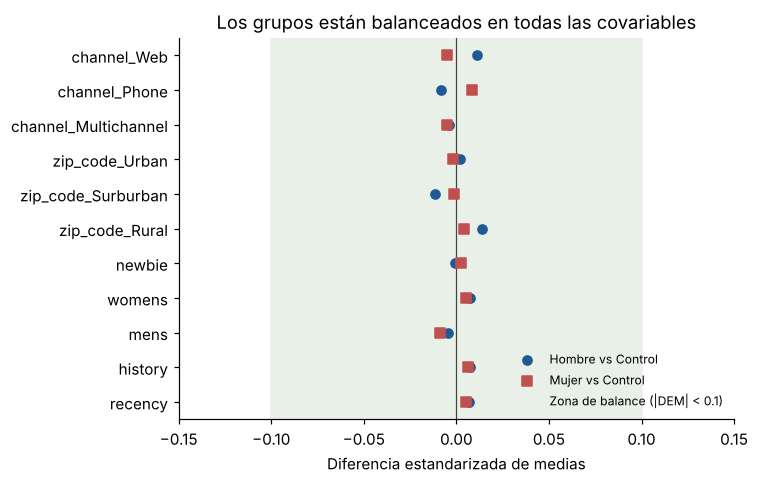

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
y = np.arange(len(balance))
ax.scatter(balance.iloc[:, 0], y, color=COLORES["Hombre"], label="Hombre vs Control", zorder=3)
ax.scatter(balance.iloc[:, 1], y, color=COLORES["Mujer"], label="Mujer vs Control", marker="s", zorder=3)
ax.axvspan(-0.1, 0.1, color="#E8F0E8", zorder=0, label="Zona de balance (|DEM| < 0.1)")
ax.axvline(0, color="#444", lw=0.8)
ax.set_yticks(y, balance.index)
ax.set_xlim(-0.15, 0.15)
ax.set_xlabel("Diferencia estandarizada de medias")
ax.set_title("Los grupos están balanceados en todas las covariables")
ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURAS / "01_balance_covariables.png", dpi=150, bbox_inches="tight")

In [9]:
print(f"Máximo |DEM|: {balance.abs().to_numpy().max():.4f}")

Máximo |DEM|: 0.0137


Todas las diferencias están muy por debajo de 0.1. La aleatorización produjo grupos comparables, así que una diferencia en los resultados se puede atribuir al correo o al azar, y separar esas dos explicaciones es justo lo que hacen las pruebas del notebook 02.

## 5. Distribución del gasto

El gasto es la métrica principal, y su forma define qué pruebas son adecuadas.

In [10]:
resumen_gasto = df.groupby("grupo", observed=True).agg(
    clientes=("spend", "size"),
    pct_con_gasto_cero=("spend", lambda s: (s == 0).mean()),
    media=("spend", "mean"),
    desv_est=("spend", "std"),
)
resumen_gasto

,clientes,pct_con_gasto_cero,media,desv_est
grupo,,,,
Control,21306,0.9943,0.6528,11.5882
Hombre,21307,0.9875,1.4226,17.7542
Mujer,21387,0.9912,1.0772,15.1161


In [11]:
percentiles = compradores.groupby("grupo", observed=True)["spend"].describe(percentiles=[0.25, 0.5, 0.75, 0.9])
percentiles

,count,mean,std,min,25%,50%,75%,90%,max
grupo,,,,,,,,,
Control,122.0000,114.0027,103.0311,29.9900,35.0400,88.3650,146.1700,226.8820,499.0000
Hombre,267.0000,113.5269,111.6828,29.9900,29.9900,66.9800,152.7200,262.7900,499.0000
Mujer,189.0000,121.8948,105.7703,29.9900,35.2000,94.7100,163.7900,268.0380,499.0000


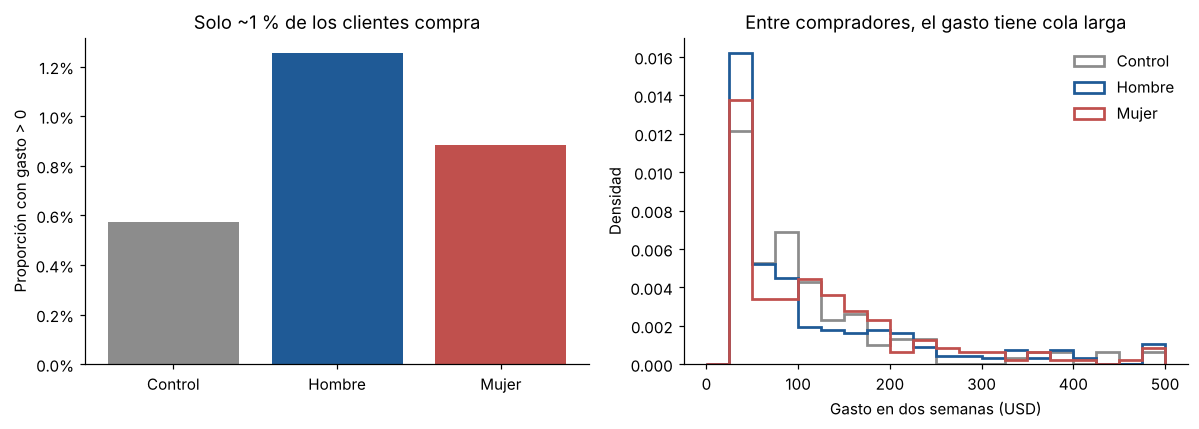

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

proporcion = df.groupby("grupo", observed=True)["conversion"].mean()
axes[0].bar(proporcion.index, proporcion.values, color=[COLORES[g] for g in proporcion.index])
axes[0].set_title("Solo ~1 % de los clientes compra")
axes[0].set_ylabel("Proporción con gasto > 0")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.1%}")

bins = np.arange(0, 525, 25)
for g in ORDEN_GRUPOS:
    axes[1].hist(compradores.loc[compradores.grupo == g, "spend"], bins=bins, histtype="step",
                 lw=1.8, color=COLORES[g], label=g, density=True)
axes[1].set_title("Entre compradores, el gasto tiene cola larga")
axes[1].set_xlabel("Gasto en dos semanas (USD)")
axes[1].set_ylabel("Densidad")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURAS / "01_distribucion_gasto.png", dpi=150, bbox_inches="tight")

Más del 99 % de los clientes no compra, y entre quienes compran el gasto va de unos pocos dólares hasta 499. Por eso:

- En el grupo control, el ingreso por cliente tiene una desviación estándar ~18 veces su media: es una métrica muy ruidosa.
- Con ~21 mil clientes por grupo, el teorema central del límite debería hacer que la diferencia de medias sea aproximadamente normal, pero lo confirmo con bootstrap en el notebook 02.
- No recorto valores extremos en el análisis principal: son compras reales y el ingreso total depende de ellas.

## 6. Poder estadístico: efecto mínimo detectable

¿Qué tan grande tenía que ser el efecto para que el experimento lo detectara con 80 % de probabilidad (α = 0.05, bilateral)? Lo calculo con la variabilidad del grupo control, que es lo que se conocería antes de lanzar la prueba.

In [13]:
n_t = int(conteos["Hombre"])
n_c = int(conteos["Control"])
base = df[df.grupo == "Control"]

filas = []
for metrica, etiqueta in [("visit", "Tasa de visita"), ("conversion", "Tasa de conversión"), ("spend", "Ingreso por cliente (USD)")]:
    media = base[metrica].mean()
    sd = base[metrica].std()
    mde = efecto_minimo_detectable(sd, n_t, n_c)
    filas.append({"metrica": etiqueta, "control": media, "mde_absoluto": mde, "mde_relativo": mde / media})

mde = pd.DataFrame(filas).set_index("metrica")
mde

,control,mde_absoluto,mde_relativo
metrica,,,
Tasa de visita,0.1062,0.0084,0.0788
Tasa de conversión,0.0057,0.0020,0.3577
Ingreso por cliente (USD),0.6528,0.3145,0.4818


Cómo leer la tabla:

- **Visita:** el experimento detecta cambios de menos de 1 punto porcentual (~8 % relativo). Tiene mucho poder.
- **Conversión:** detecta cambios de ~0.2 puntos, que equivalen a ~36 % relativo, porque la tasa base es muy baja.
- **Ingreso por cliente:** solo detecta efectos de ~0.31 USD por cliente, casi la mitad del ingreso del control (~48 % relativo).

Esto define la interpretación: si una campaña no muestra un efecto significativo en ingreso, no significa que no funcione. Puede ser un efecto real más chico que lo detectable. Para los segmentos, que tienen menos clientes, el poder es todavía menor.

## Conclusión

| Revisión | Resultado |
|---|---|
| Calidad de datos | Sin nulos ni inconsistencias; gasto con tope en 499 USD (12 casos) |
| Sample ratio mismatch | Sin desbalance (p = 0.90) |
| Balance de covariables | Todas las \|DEM\| < 0.02 |
| Distribución del gasto | >99 % ceros y cola larga; se usará Welch + bootstrap |
| Poder | Alto para visita, bajo para ingreso (MDE ≈ 48 % del control) |

El experimento es válido para analizarse como aleatorizado. Siguiente paso: [`02_analisis.ipynb`](02_analisis.ipynb).